# Ising模型のモンテカルロシミュレーション

2次元正方格子のIsing模型をMetropolis法で調べます。Notebookを最初から順に実行してください。乱数seedを固定しているので、同じ環境では同じ系列を再現できます。

## 1. 模型と単位

スピンは $s_{ij}=\pm1$、最近接相互作用は強磁性 $J>0$ とします。外場は $h=0$、境界は周期的です。

$$
H=-J\sum_{\langle ab\rangle}s_as_b,
\qquad
\beta=\frac{1}{k_{\rm B}T},
\qquad
\Delta E=2Js_{ij}\sum_{\text{4近傍}}s_{ab}.
$$

以下では $J=k_{\rm B}=1$ の換算単位を使い、温度変数として $k_{\rm B}T/J$ を指定します。有限系では $\langle m\rangle$ は対称性で0になり得るため、秩序の大きさには $\langle|m|\rangle$ を使います。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261215)
L = 20
N = L**2
J = 1.0
k_B = 1.0

## 2. エネルギー差と受理確率

一回の試行で格子点を一様に選び、そのスピンを反転させます。Metropolis受理確率は
$$
P_{\rm acc}=\min(1,e^{-\beta\Delta E}).
$$
エネルギーが下がる反転は必ず受理し、上がる反転も確率的に受理します。

In [2]:
def total_energy(spins):
    # 各結合を右向き・上向きに一度ずつ数える
    return -J * np.sum(
        spins * (np.roll(spins, -1, axis=0)
                 + np.roll(spins, -1, axis=1))
    )

def flip_energy_change(spins, i, j):
    neighbors = (spins[(i - 1) % L, j] + spins[(i + 1) % L, j]
                 + spins[i, (j - 1) % L] + spins[i, (j + 1) % L])
    return 2 * J * spins[i, j] * neighbors

def metropolis_attempt(spins, temperature, rng):
    i, j = rng.integers(L, size=2)
    dE = flip_energy_change(spins, i, j)
    accepted = dE <= 0 or rng.random() < np.exp(-dE / (k_B * temperature))
    if accepted:
        spins[i, j] *= -1
    return accepted

In [3]:
# 局所式と全エネルギー差が一致することを確かめる
test_spins = rng.choice((-1, 1), size=(L, L)).astype(np.int8)
i, j = 4, 7
before = total_energy(test_spins)
dE_local = flip_energy_change(test_spins, i, j)
test_spins[i, j] *= -1
assert np.isclose(total_energy(test_spins) - before, dE_local)
assert dE_local in (-8 * J, -4 * J, 0.0, 4 * J, 8 * J)

## 3. 平衡化と測定

「1試行」はスピン1個を反転候補にする操作です。$N=L^2$ 回の試行を1 Monte Carlo sweepと呼ぶことがあります。初期条件の影響を減らすため最初の区間を捨てる（バーンイン）ことと、平衡後の自己相関を減らすことは別です。測定間隔を広げても、サンプルが独立になる保証はありません。

In [4]:
def simulate(temperature, n_attempts, sample_every, initial_spin=1):
    spins = np.full((L, L), initial_spin, dtype=np.int8)
    accepted = 0
    m_samples, e_samples = [], []
    for step in range(n_attempts):
        accepted += metropolis_attempt(spins, temperature, rng)
        if (step + 1) % sample_every == 0:
            m_samples.append(np.mean(spins))
            e_samples.append(total_energy(spins) / N)
    return (spins, np.asarray(m_samples), np.asarray(e_samples),
            accepted / n_attempts)

## 4. 自己相関と熱平衡化

観測量 $A$ の規格化自己相関は
$$
C_A(\ell)=
\frac{\langle(A_t-\langle A\rangle)
(A_{t+\ell}-\langle A\rangle)\rangle}
{\langle(A_t-\langle A\rangle)^2\rangle}.
$$
相関が長く残る臨界点付近では、受理率だけから独立サンプル間隔は決められません。以下の系列も、時間相関を持つ実データです。

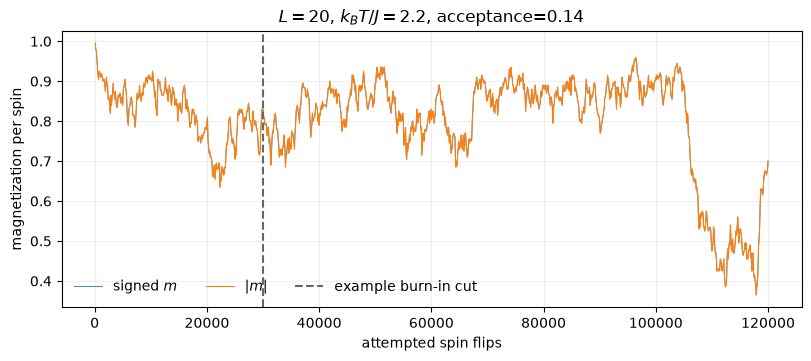

In [5]:
T_trace = 2.2
spins, m_trace, e_trace, acceptance = simulate(
    T_trace, n_attempts=120_000, sample_every=100
)
steps = np.arange(100, 120_001, 100)
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(steps, m_trace, lw=0.6, label=r"signed $m$")
ax.plot(steps, np.abs(m_trace), lw=0.8, label=r"$|m|$")
ax.axvline(30_000, color="0.4", ls="--", label="example burn-in cut")
ax.set(xlabel="attempted spin flips", ylabel="magnetization per spin",
       title=rf"$L={L}$, $k_BT/J={T_trace}$, acceptance={acceptance:.2f}")
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=0.2)
plt.show()

In [6]:
print(f"受理率 = {acceptance:.3f}")
print(f"L^2 / 受理率 = {L**2 / acceptance:.0f} 試行（全サイト更新の粗い目安）")

受理率 = 0.142
L^2 / 受理率 = 2815 試行（全サイト更新の粗い目安）


$L^2/\text{受理率}$ は全サイトに一度程度の受理反転が起こるまでの粗い時間尺度にすぎません。独立性や緩和時間の測定値ではありません。実際の相関時間は、観測量の系列や自己相関関数から評価します。

## 5. 温度依存性

$h=0$ の無限正方格子では
$$
\frac{k_{\rm B}T_c}{J}=\frac{2}{\ln(1+\sqrt2)}\simeq2.269,
\qquad
m(T)=
\begin{cases}
[1-\sinh^{-4}(2J/k_{\rm B}T)]^{1/8},&T<T_c,\\
0,&T\ge T_c.
\end{cases}
$$
有限サイズの $\langle|m|\rangle$ は高温でも0にならず、転移も丸まります。有限系の結果と無限系の厳密解を区別して比較します。

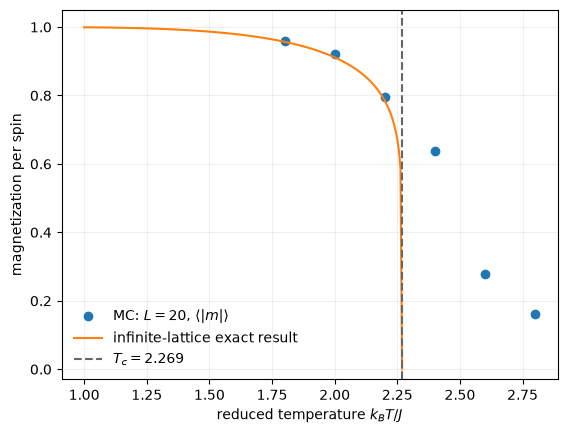

In [7]:
temperatures = np.array([1.8, 2.0, 2.2, 2.4, 2.6, 2.8])
mean_abs_m = []
for T in temperatures:
    _, m, _, _ = simulate(T, n_attempts=180_000,
                          sample_every=1_000, initial_spin=1)
    mean_abs_m.append(np.mean(np.abs(m[30:])))  # 初期30,000試行を除く

Tc = 2 / np.log(1 + np.sqrt(2))
T_exact = np.linspace(1.0, Tc, 200)
m_exact = (1 - np.sinh(2 / T_exact)**-4)**(1 / 8)
plt.plot(temperatures, mean_abs_m, "o", label=r"MC: $L=20$, $\langle|m|\rangle$")
plt.plot(T_exact, m_exact, label="infinite-lattice exact result")
plt.axvline(Tc, color="0.4", ls="--", label=rf"$T_c={Tc:.3f}$")
plt.xlabel(r"reduced temperature $k_BT/J$")
plt.ylabel("magnetization per spin")
plt.ylim(-0.03, 1.05)
plt.grid(alpha=0.2)
plt.legend(frameon=False)
plt.show()

## 6. 演習：揺らぎから物理量を求める

磁化の二乗平均 <m²> と、1スピンあたりの比熱
C_V/N = β²(<E²> - <E>²)/N を温度ごとに見積もります。
測定値は自己相関を持つので、統計誤差を独立サンプルの式だけで評価しないこと。

In [ ]:
# TODO: 各温度で平衡化後の m_samples, e_samples を集め、
# mean(m**2) と beta**2 * var(E_total) / N を計算する。